# Dish Localization

Fine-tunes YOLOv8n on food tray dataset using GPU.

### Config

In [42]:
DATASET         = "/content/yolov8"
DATASET_YAML    = f"{DATASET}/data.yaml"
DATASET_PATH    = Path(DATASET)
MODEL           = "yolov8n.pt"
EPOCHS          = 100
BATCH           = 16
IMG_SIZE        = 640
PROJECT         = "/content/runs"
RUN_NAME        = "food_tray_v1"
CONF            = 0.35
N_PREVIEW       = 5

CLASS_NAMES  = ["drink", "food", "meatless soup", "rice_big", "rice_small", "soup"]
CLASS_COLORS = {
    0: ( 56, 182, 255),   # drink
    1: ( 56, 255, 120),   # food
    2: (200,  56, 255),   # meatless soup
    3: (255, 200,  56),   # rice_big
    4: (255, 100,  56),   # rice_small
    5: (255, 100,  56),   # soup
}

### import libraries

In [18]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "ultralytics", "--quiet"])

import random
import shutil
import yaml
import cv2
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path
from ultralytics import YOLO
from google.colab import drive, files

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


### Helpers

In [19]:
def verify_dataset():
    base       = DATASET_PATH
    train_imgs = list((base / "images" / "train").glob("*.*"))
    val_imgs   = list((base / "images" / "val").glob("*.*"))
    train_lbls = list((base / "labels" / "train").glob("*.txt"))
    val_lbls   = list((base / "labels" / "val").glob("*.txt"))

    print("\nDataset summary")
    print(f"  classes      : {CLASS_NAMES}")
    print(f"  train images : {len(train_imgs)}")
    print(f"  train labels : {len(train_lbls)}")
    print(f"  val   images : {len(val_imgs)}")
    print(f"  val   labels : {len(val_lbls)}")

    if len(train_imgs) == 0:
        raise RuntimeError("No training images found — check your Drive folder structure.")
    if len(train_imgs) != len(train_lbls):
        print("  [warn] image/label count mismatch in train set")

    print("\nDataset OK.")

In [20]:
def train():
    import torch
    print(f"\nGPU : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT FOUND — check Runtime type'}")

    model = YOLO(MODEL)
    model.train(
        data      = DATASET_YAML,
        epochs    = EPOCHS,
        batch     = BATCH,
        imgsz     = IMG_SIZE,
        device    = 0,
        project   = PROJECT,
        name      = RUN_NAME,
        exist_ok  = True,
        freeze    = 10,
        optimizer = "AdamW",
        lr0       = 0.001,
        lrf       = 0.01,
        patience  = 15,
        hsv_h     = 0.015,
        hsv_s     = 0.7,
        hsv_v     = 0.4,
        fliplr    = 0.5,
        translate = 0.1,
        scale     = 0.5,
        mosaic    = 0.5,
        verbose   = True,
        plots     = True,
    )

    best = Path(PROJECT) / RUN_NAME / "weights" / "best.pt"
    print(f"\nBest model saved to: {best}")
    return best

In [21]:
def evaluate(model_path):
    model   = YOLO(model_path)
    metrics = model.val(data=DATASET_YAML, device=0, verbose=True)

    print("\nResults")
    print(f"  mAP50     : {metrics.box.map50:.3f}  (target > 0.70)")
    print(f"  mAP50-95  : {metrics.box.map:.3f}")
    print(f"  Precision : {metrics.box.mp:.3f}")
    print(f"  Recall    : {metrics.box.mr:.3f}")

    if   metrics.box.map50 >= 0.70: print("\n  Good — ready to deploy.")
    elif metrics.box.map50 >= 0.50: print("\n  Acceptable. More labeled images will improve results.")
    else:                           print("\n  Low accuracy. Collect more labeled images.")

    return metrics

In [22]:
def show_training_curves(run_dir):
    for plot_name in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
        plot = run_dir / plot_name
        if plot.exists():
            fig, ax = plt.subplots(figsize=(14, 6))
            ax.imshow(mpimg.imread(str(plot)))
            ax.axis("off")
            ax.set_title(plot_name)
            plt.tight_layout()
            plt.show()

In [23]:
def draw_boxes(image, boxes):
    for box in boxes:
        cls_id          = int(box.cls[0])
        conf            = float(box.conf[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        color           = CLASS_COLORS.get(cls_id, (255, 255, 255))
        label           = f"{CLASS_NAMES[cls_id]} {conf:.0%}"

        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
        cv2.rectangle(image, (x1, y1 - th - 8), (x1 + tw + 4, y1), color, -1)
        cv2.putText(image, label, (x1 + 2, y1 - 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    return image

In [24]:
def detection_preview(model_path, conf=CONF, n=N_PREVIEW):
    model      = YOLO(model_path)
    val_dir    = DATASET_PATH / "images" / "val"
    image_exts = {".jpg", ".jpeg", ".png", ".bmp"}
    all_imgs   = [p for p in val_dir.rglob("*") if p.suffix.lower() in image_exts]

    if not all_imgs:
        print(f"No images in {val_dir}")
        return

    samples = random.sample(all_imgs, min(n, len(all_imgs)))

    for img_path in samples:
        image   = cv2.imread(str(img_path))
        results = model(image, conf=conf, verbose=False)[0]
        boxes   = results.boxes

        print(f"\n{img_path.name}  —  {len(boxes)} detection(s)")
        for box in boxes:
            print(f"  {CLASS_NAMES[int(box.cls[0])]:<20} {float(box.conf[0]):.1%}")

        annotated = draw_boxes(image.copy(), boxes)
        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        plt.title(img_path.name)
        plt.axis("off")
        plt.tight_layout()
        plt.show()

In [25]:
def download_model(model_path, run_dir):
    bundle = Path("/content/model_export")
    bundle.mkdir(exist_ok=True)

    shutil.copy2(model_path, bundle / "best.pt")

    for plot in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
        src = run_dir / plot
        if src.exists():
            shutil.copy2(src, bundle / plot)

    zip_path = "/content/food_tray_model"
    shutil.make_archive(zip_path, "zip", bundle)

    print("Downloading food_tray_model.zip ...")
    files.download(zip_path + ".zip")

# Running code

In [35]:
import zipfile, shutil
from pathlib import Path

extract_dir = Path("/content/YOLOlabels")
if extract_dir.exists():
    shutil.rmtree(extract_dir)

with zipfile.ZipFile("/content/YOLOlabels.zip", "r") as zf:
    zf.extractall("/content/")

# Show what was extracted
for p in sorted(Path("/content").rglob("*"))[:40]:
    print(p)

/content/.config
/content/.config/.last_opt_in_prompt.yaml
/content/.config/.last_survey_prompt.yaml
/content/.config/.last_update_check.json
/content/.config/active_config
/content/.config/config_sentinel
/content/.config/configurations
/content/.config/configurations/config_default
/content/.config/default_configs.db
/content/.config/gce
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/logs
/content/.config/logs/2026.05.12
/content/.config/logs/2026.05.12/13.34.42.645568.log
/content/.config/logs/2026.05.12/13.35.03.183347.log
/content/.config/logs/2026.05.12/13.35.13.861801.log
/content/.config/logs/2026.05.12/13.35.15.619517.log
/content/.config/logs/2026.05.12/13.35.26.553372.log
/content/.config/logs/2026.05.12/13.35.27.356656.log
/content/YOLOlabels.zip
/content/sample_data
/content/sample_data/README.md
/content/sample_data/anscombe.json
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train

In [45]:
data = {
    "path":  "/content/yolov8",
    "train": "images/train",
    "val":   "images/val",
    "nc":    6,
    "names": ["drink", "food", "meatless soup", "rice_big", "rice_small", "soup"],
}

with open(DATASET_YAML, "w") as f:
    yaml.dump(data, f, default_flow_style=False, sort_keys=False)

print(open(DATASET_YAML).read())

path: /content/yolov8
train: images/train
val: images/val
nc: 6
names:
- drink
- food
- meatless soup
- rice_big
- rice_small
- soup




Dataset summary
  classes      : ['drink', 'food', 'meatless soup', 'rice_big', 'rice_small', 'soup']
  train images : 119
  train labels : 119
  val   images : 22
  val   labels : 22

Dataset OK.

GPU : Tesla T4
Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolov8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, 

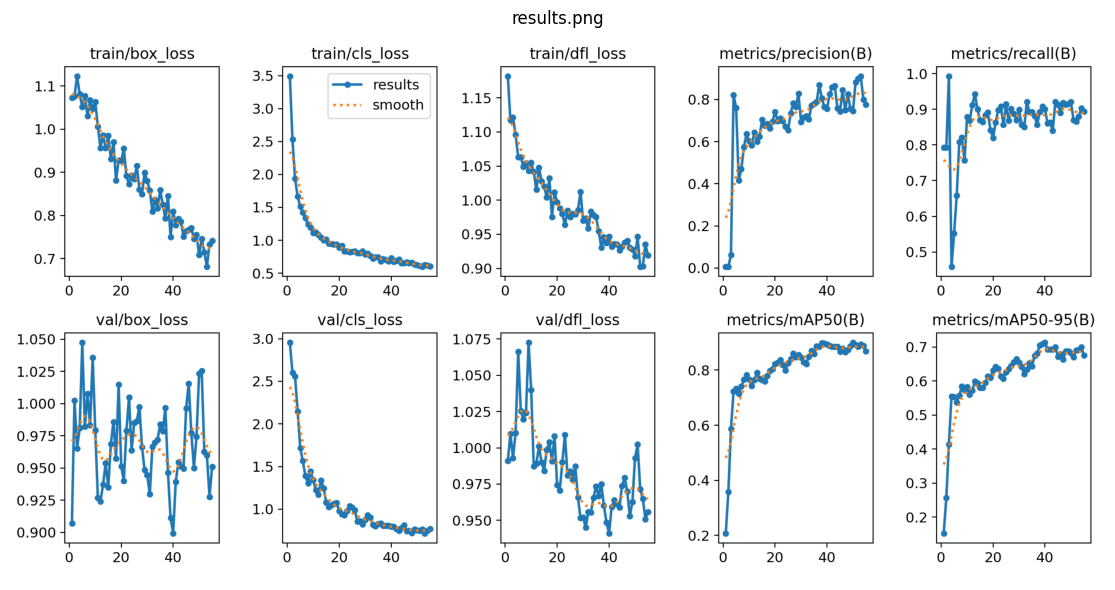

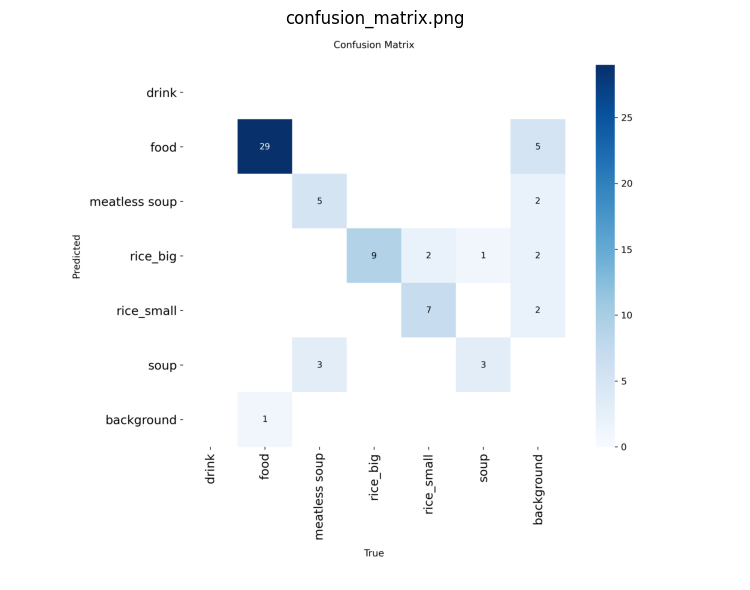

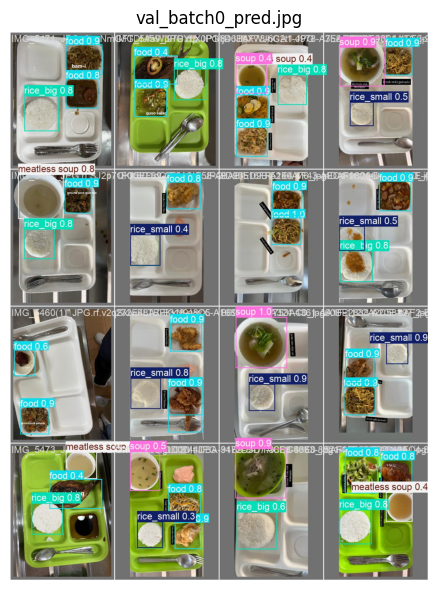


4DAF9804-D803-471E-A322-A6F3D357C923_jpg.rf.bsjoIT0fvlqPHS20qxXJ.jpg  —  3 detection(s)
  food                 94.7%
  rice_big             81.7%
  rice_small           41.2%


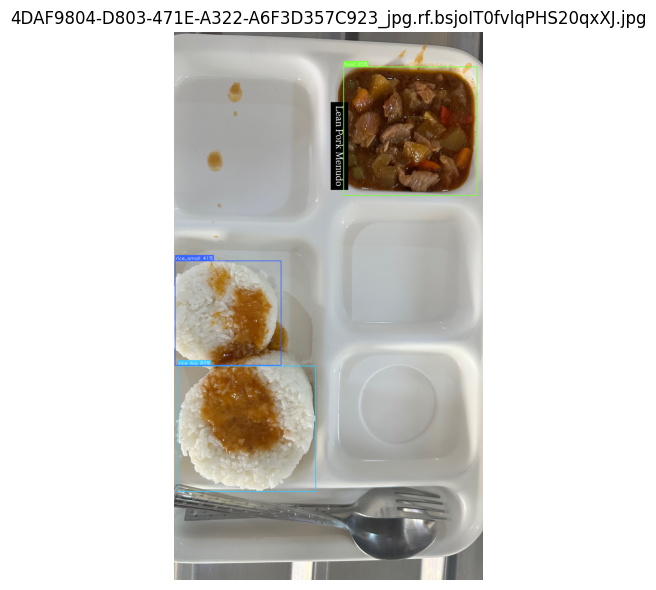


IMG_5460(1)_JPG.rf.v2qSxIviFLTBFKxN9wwX.JPG  —  2 detection(s)
  food                 83.8%
  food                 42.3%


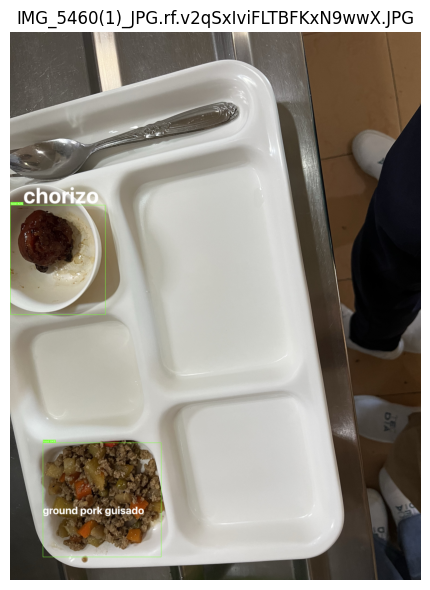


IMG_5459_JPG.rf.X0P1iIjDJJlcXWJhG2t1.JPG  —  2 detection(s)
  food                 85.4%
  rice_big             84.0%


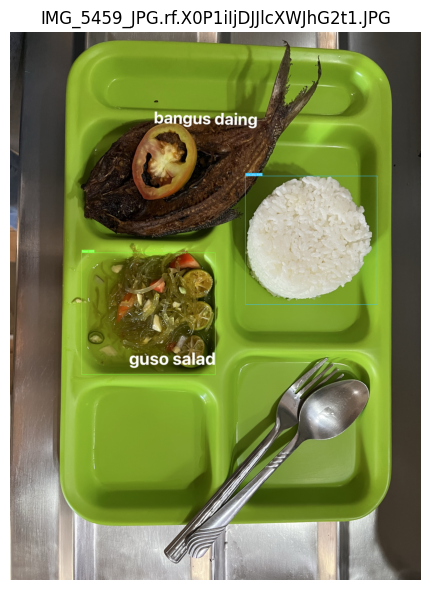


3EAB7AA0-4061-4C56-9919-7B7E02378054_jpg.rf.l9Tt88d7XznZamdEzHmR.jpg  —  3 detection(s)
  soup                 94.7%
  food                 93.6%
  rice_small           49.1%


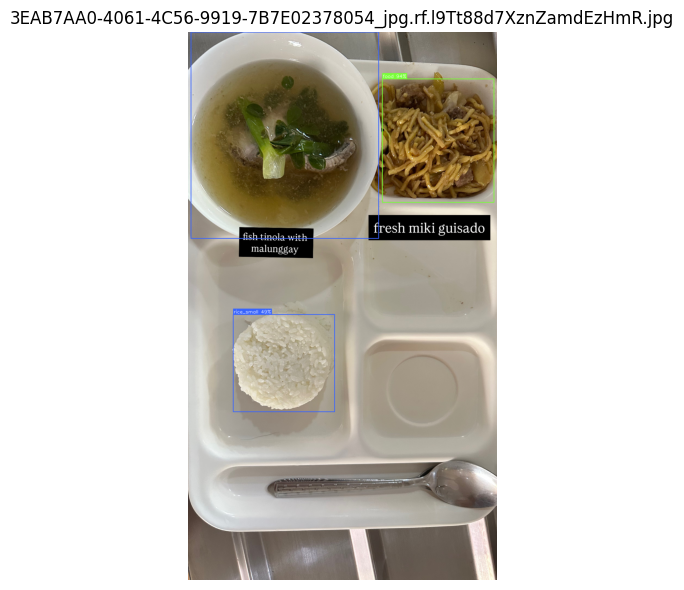


1FC5EF69-0F3A-4F58-ABAB-516FFA146A76_jpg.rf.8ssjimGiGOX7zuZ39on5.jpg  —  3 detection(s)
  food                 83.9%
  rice_small           51.2%
  rice_big             42.2%


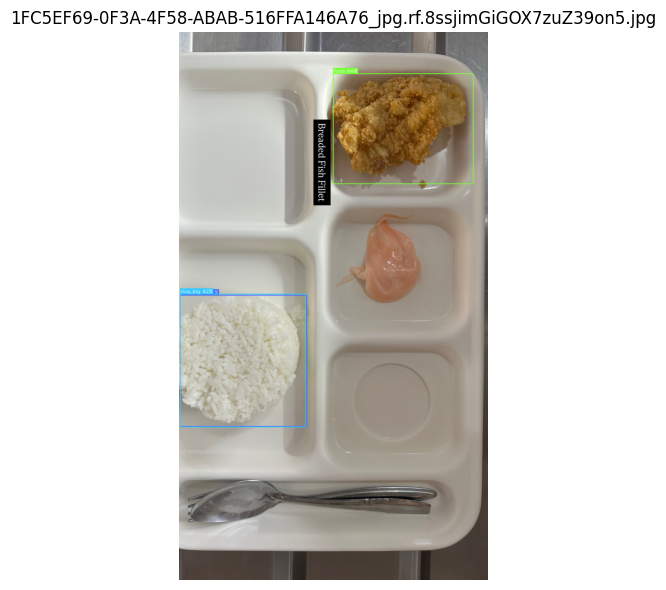

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
verify_dataset()
best_model_path = train()
run_dir         = Path(PROJECT) / RUN_NAME
evaluate(best_model_path)
show_training_curves(run_dir)
detection_preview(best_model_path)
download_model(best_model_path, run_dir)

In [38]:
for p in sorted(Path("/content").rglob("*"))[:50]:
    print(p)

/content/.config
/content/.config/.last_opt_in_prompt.yaml
/content/.config/.last_survey_prompt.yaml
/content/.config/.last_update_check.json
/content/.config/active_config
/content/.config/config_sentinel
/content/.config/configurations
/content/.config/configurations/config_default
/content/.config/default_configs.db
/content/.config/gce
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/logs
/content/.config/logs/2026.05.12
/content/.config/logs/2026.05.12/13.34.42.645568.log
/content/.config/logs/2026.05.12/13.35.03.183347.log
/content/.config/logs/2026.05.12/13.35.13.861801.log
/content/.config/logs/2026.05.12/13.35.15.619517.log
/content/.config/logs/2026.05.12/13.35.26.553372.log
/content/.config/logs/2026.05.12/13.35.27.356656.log
/content/YOLOlabels.zip
/content/sample_data
/content/sample_data/README.md
/content/sample_data/anscombe.json
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train